#### Prelimnary Analysis - Seaborn + plotly
<pre>
1) Check null values and duplicates in each df.
2) Find Count of Customers from each city and represent it on bar chart.
3) Find Range Age wise count of cutsomers, represent it on pie chart.
4) Find Count of each activity, represent it on bar chart
5) Find order month wise total amount. Represent it on line chart.
6) Find Sub_Plan wise total revenue generated. Represent it on bar chart.
7) City wise find total amount
8) Find count of each payment mode, represent it on donut chart
9) Represent Payment mode wise sum of amount on a strip plot

</pre>
#### Objective - Funnel Analysis
<pre>
1) Generate the Entire Funnel. Represent 4 columns
- Funnel_Stage, Count_of_Cust, Percenatge_Conversion

2) Find Customer wise count of days to transition from one stage of funnel to the next stage

3) Find Avg_Days to transition from one Funnel stage to the next stage.

4) Create function to analyse Funnel based on City.

</pre>


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# telco = pd.read_csv('C:\\Users\\DELL\\Downloads\\Imarticus_Work\\PGA40\\ANN\\telco_churn.csv')
# telco.head()

In [3]:
ca = pd.read_csv('cust_activity.csv')
cb = pd.read_csv('cust_bio.csv')  
cs = pd.read_csv('cust_sub.csv')
orders = pd.read_csv('orders.csv')  
sp = pd.read_csv('sp.csv')

In [4]:
print(ca.shape)
print(cb.shape)
print(cs.shape)
print(orders.shape)
print(sp.shape)

(7500, 3)
(478, 3)
(51, 3)
(127, 4)
(6, 5)


In [5]:
print(ca.columns)
print(cb.columns)
print(cs.columns)
print(orders.columns)
print(sp.columns)

Index(['Cust_ID', 'Activity', 'Date'], dtype='str')
Index(['Cust_ID', 'City', 'Age'], dtype='str')
Index(['Cust_ID', 'Plan_Var_ID', 'Purchase_Date'], dtype='str')
Index(['Order_id', 'Cust_ID', 'Amount', 'Payment_mode'], dtype='str')
Index(['Plan_Var_ID', 'Plan_ID', 'Plan_name', 'Price', 'Duration'], dtype='str')


#### 1) Check null values and duplicates in each df.

In [6]:
for i in [ca,cb,cs,orders,sp]:
    print(i.isnull().sum())  

Cust_ID     0
Activity    0
Date        0
dtype: int64
Cust_ID    0
City       0
Age        0
dtype: int64
Cust_ID          0
Plan_Var_ID      0
Purchase_Date    0
dtype: int64
Order_id        0
Cust_ID         0
Amount          0
Payment_mode    0
dtype: int64
Plan_Var_ID    0
Plan_ID        0
Plan_name      0
Price          0
Duration       0
dtype: int64


In [7]:
def check_dup(data):      # data is dataframe
    dup = data.duplicated().sum()
    if dup > 0:
        print(dup)
    else:
        print('No Duplicates')  

In [8]:
for i in [ca,cb,cs,orders,sp]:
    check_dup(i)

No Duplicates
No Duplicates
No Duplicates
No Duplicates
No Duplicates


In [9]:
# !pip install plotly

In [10]:
import plotly.express as px

#### Q2) Find Count of Customers from each city and represent it on bar chart.

In [11]:
q2 =  cb['City'].value_counts().reset_index()
q2

,City,count
0,Chennai,109
1,Delhi,106
2,Kolkata,94
3,Noida,92
4,Mumbai,77


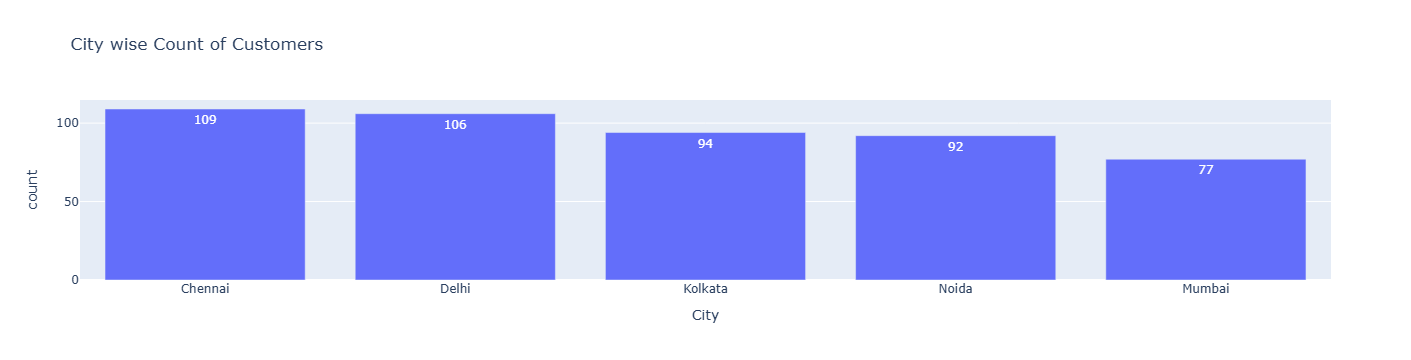

In [12]:
fig = px.bar(data_frame = q2, x = 'City',y ='count',title='City wise Count of Customers',
             text='count')  
fig.show() 

#### Q3) Find Range Age wise count of customers, represent it on pie chart.

In [13]:
cb['Age'].describe()

count    478.000000
mean      28.740586
std        5.376756
min       20.000000
25%       24.000000
50%       29.000000
75%       34.000000
max       37.000000
Name: Age, dtype: float64

In [14]:
cb['Age_Range'] = pd.cut(cb['Age'], bins = [19,24,29,34,39])
cb['Age_Range'] = cb['Age_Range'].astype(str)  

In [15]:
q3  = cb['Age_Range'].value_counts().reset_index()  
q3

,Age_Range,count
0,"(19, 24]",137
1,"(29, 34]",130
2,"(24, 29]",120
3,"(34, 39]",91


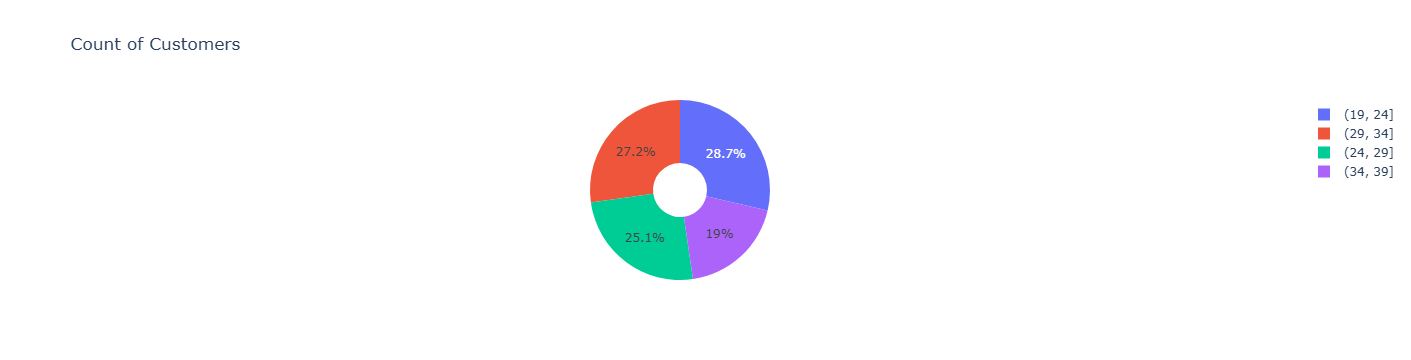

In [16]:
fig =  px.pie(data_frame=q3, names = 'Age_Range',values = 'count',title='Count of Customers',hole=0.3)
fig.show()

#### Q4) Find Count of each activity, represent it on bar chart

In [17]:
ca.columns

Index(['Cust_ID', 'Activity', 'Date'], dtype='str')

In [18]:
q4 = ca['Activity'].value_counts().reset_index()  
q4       

,Activity,count
0,Browse,6548
1,Sign_Up,478
2,Add_to_Cart,287
3,Checkout,127
4,Review,40
5,Return/Refund,20


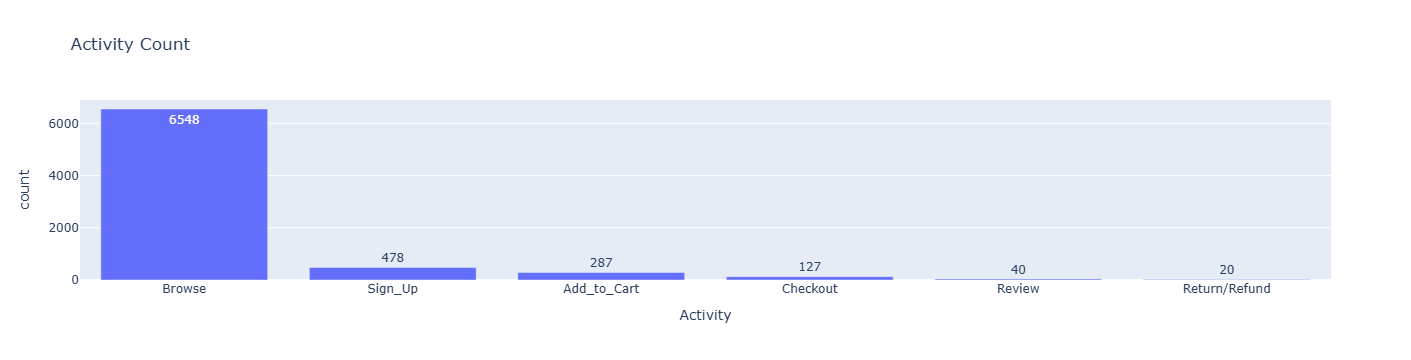

In [19]:
fig =  px.bar(data_frame=q4, x='Activity',y='count',                                    
              title='Activity Count',text='count')  # text is used to display data labels
fig.show()   

#### Q5) Find order month wise total amount. Represent it on line chart.

In [20]:
print(ca.columns)
print(orders.columns)

Index(['Cust_ID', 'Activity', 'Date'], dtype='str')
Index(['Order_id', 'Cust_ID', 'Amount', 'Payment_mode'], dtype='str')


In [21]:
print(ca.shape)
print(orders.shape)

(7500, 3)
(127, 4)


In [22]:
ca.head()

,Cust_ID,Activity,Date
0,CUS_121,Sign_Up,2024-04-24
1,CUS_121,Browse,2024-04-27
2,CUS_121,Add_to_Cart,2024-04-27
3,CUS_121,Browse,2024-04-29
4,CUS_121,Browse,2024-04-30


In [23]:
ca.dtypes

Cust_ID     str
Activity    str
Date        str
dtype: object

In [24]:
ca['Date'] = pd.to_datetime(ca['Date'])
ca['Month'] = ca['Date'].dt.month   

In [25]:
ca_checkout = ca[ca['Activity']=='Checkout']
print(ca_checkout.shape)   
print(orders.shape)  

(127, 4)
(127, 4)


In [26]:
ca_orders = pd.merge(orders, ca_checkout, on='Cust_ID',how='inner')
ca_orders.head()  

,Order_id,Cust_ID,Amount,Payment_mode,Activity,Date,Month
0,ORD_71,CUS_545,2123.19,UPI,Checkout,2024-04-26,4
1,ORD_72,CUS_622,2788.02,Net Banking,Checkout,2024-02-01,2
2,ORD_73,CUS_418,3071.63,Credit_Card,Checkout,2024-07-22,7
3,ORD_74,CUS_360,5736.31,COD,Checkout,2025-05-24,5
4,ORD_75,CUS_714,1592.53,Debit Card,Checkout,2024-06-19,6


In [27]:
q5 = ca_orders.groupby(['Month'])['Amount'].sum().reset_index()    
q5  

,Month,Amount
0,1,27022.20
1,2,70477.42
2,3,74777.59
3,4,88080.66
4,5,60200.46
5,6,69580.07
6,7,80416.05
7,8,27227.29
8,9,34804.62
9,10,30298.38


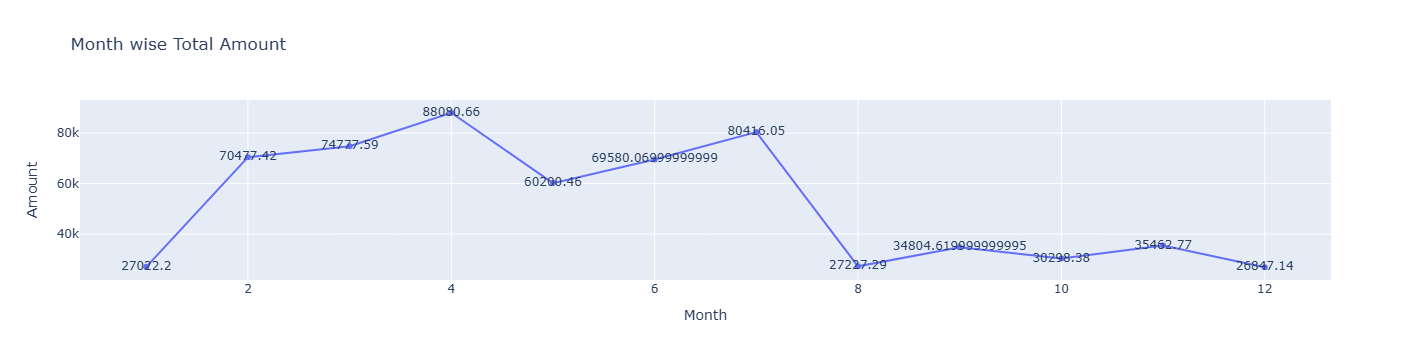

In [28]:
fig = px.line(data_frame=q5,x='Month',y='Amount',title='Month wise Total Amount',
              text='Amount')
fig.show()

#### Q6) Find Sub_Plan wise total revenue generated. Represent it on bar chart.

In [29]:
print(sp.columns)
print(cs.columns)

Index(['Plan_Var_ID', 'Plan_ID', 'Plan_name', 'Price', 'Duration'], dtype='str')
Index(['Cust_ID', 'Plan_Var_ID', 'Purchase_Date'], dtype='str')


In [30]:
print(sp.shape)
print(cs.shape)

(6, 5)
(51, 3)


In [31]:
# cs.head()

In [32]:
cs_sp = pd.merge(cs,sp,on='Plan_Var_ID',how='inner')  
cs_sp.head()  

,Cust_ID,Plan_Var_ID,Purchase_Date,Plan_ID,Plan_name,Price,Duration
0,CUS_626,P1_1Y,2025-05-15,P1,Silver,1200.0,1 Year
1,CUS_723,P1_1Y,2024-07-23,P1,Silver,1200.0,1 Year
2,CUS_575,P1_1Y,2024-11-14,P1,Silver,1200.0,1 Year
3,CUS_232,P2_6M,2025-04-19,P2,Gold,1440.0,6 Months
4,CUS_346,P2_1Y,2024-01-31,P2,Gold,2400.0,1 Year


In [33]:
q6 = cs_sp.groupby(['Plan_Var_ID'])['Price'].sum().reset_index()  
q6

,Plan_Var_ID,Price
0,P1_1Y,16800.0
1,P1_6M,5040.0
2,P2_1Y,24000.0
3,P2_6M,7200.0
4,P3_1Y,28800.0
5,P3_6M,25920.0


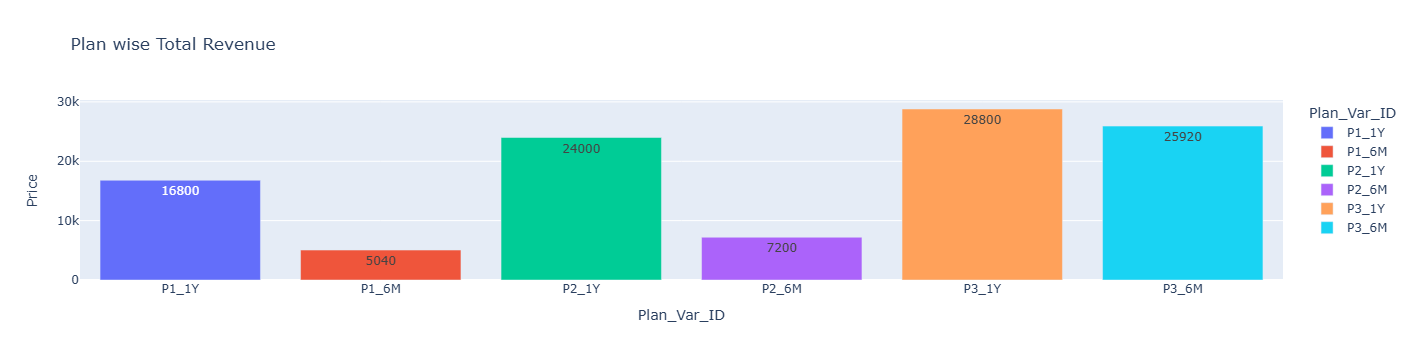

In [34]:
fig = px.bar(data_frame=q6, x='Plan_Var_ID',y ='Price',   
             title='Plan wise Total Revenue',color='Plan_Var_ID',   
             text='Price')
fig.show()

#### Funnel Analysis

#### 1) Generate the Entire Funnel. Represent 4 columns
- Funnel_Stage, Count_of_Cust, Percenatge_Conversion

In [43]:
ca.head()

,Cust_ID,Activity,Date,Month
0,CUS_121,Sign_Up,2024-04-24,4
1,CUS_121,Browse,2024-04-27,4
2,CUS_121,Add_to_Cart,2024-04-27,4
3,CUS_121,Browse,2024-04-29,4
4,CUS_121,Browse,2024-04-30,4


In [44]:
ca['Activity'].value_counts()

Activity
Browse           6548
Sign_Up           478
Add_to_Cart       287
Checkout          127
Review             40
Return/Refund      20
Name: count, dtype: int64

In [45]:
w1 =  ca.groupby(['Cust_ID','Activity'])['Activity'].count().reset_index(name='Count')
w1.head()    

,Cust_ID,Activity,Count
0,CUS_121,Add_to_Cart,1
1,CUS_121,Browse,8
2,CUS_121,Checkout,1
3,CUS_121,Sign_Up,1
4,CUS_122,Browse,10


In [46]:
funnel = w1['Activity'].value_counts().reset_index()
funnel

,Activity,count
0,Browse,681
1,Sign_Up,478
2,Add_to_Cart,287
3,Checkout,127
4,Review,40
5,Return/Refund,20


In [47]:
funnel['Prev_Count'] = np.where(funnel['Activity']=='Return/Refund', 
                                funnel['count'].shift(2),
                                funnel['count'].shift(1))
funnel

,Activity,count,Prev_Count
0,Browse,681,NaN
1,Sign_Up,478,681.0
2,Add_to_Cart,287,478.0
3,Checkout,127,287.0
4,Review,40,127.0
5,Return/Refund,20,127.0


In [48]:
funnel['Per_Conversion'] = round((funnel['count']/funnel['Prev_Count'])*100,2)  
funnel.fillna(0,inplace=True)
funnel

,Activity,count,Prev_Count,Per_Conversion
0,Browse,681,0.0,0.00
1,Sign_Up,478,681.0,70.19
2,Add_to_Cart,287,478.0,60.04
3,Checkout,127,287.0,44.25
4,Review,40,127.0,31.50
5,Return/Refund,20,127.0,15.75


In [49]:
funnel['Per_Conversion'] = funnel['Per_Conversion'].apply(lambda x : str(x) + '%')   
funnel

,Activity,count,Prev_Count,Per_Conversion
0,Browse,681,0.0,0.0%
1,Sign_Up,478,681.0,70.19%
2,Add_to_Cart,287,478.0,60.04%
3,Checkout,127,287.0,44.25%
4,Review,40,127.0,31.5%
5,Return/Refund,20,127.0,15.75%


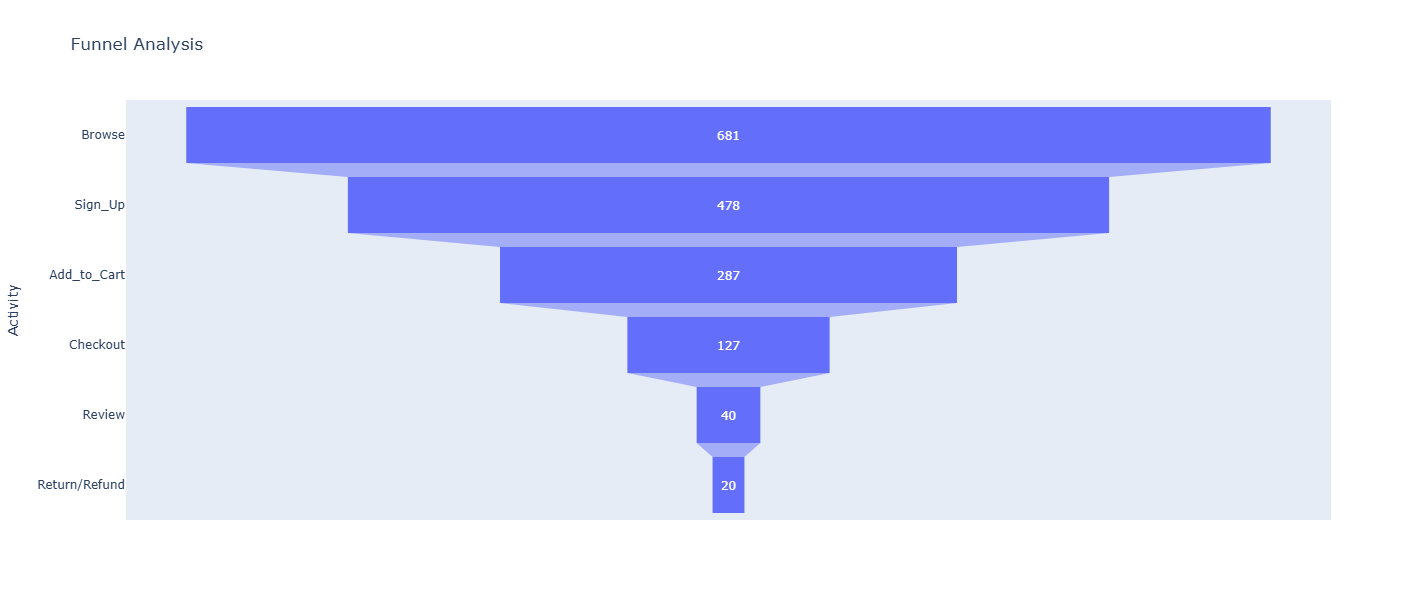

In [50]:
fig  = px.funnel(data_frame=funnel,y='Activity',x='count'
                 ,title='Funnel Analysis',height=600,hover_data='Per_Conversion')  
fig.show()   

#### Q2) Find Customer wise count of days to transition from one stage of funnel to the next stage

In [51]:
ca.head(20)

,Cust_ID,Activity,Date,Month
0,CUS_121,Sign_Up,2024-04-24,4
1,CUS_121,Browse,2024-04-27,4
2,CUS_121,Add_to_Cart,2024-04-27,4
3,CUS_121,Browse,2024-04-29,4
4,CUS_121,Browse,2024-04-30,4
5,CUS_121,Browse,2024-05-04,5
6,CUS_121,Checkout,2024-05-05,5
7,CUS_121,Browse,2024-05-07,5
8,CUS_121,Browse,2024-05-09,5
9,CUS_121,Browse,2024-05-10,5


In [52]:
pt1 = pd.pivot_table(data=ca,index=['Cust_ID'],columns=['Activity'],
                     values='Date', aggfunc='min')  
pt1.head(15)

Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up
Cust_ID,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15
CUS_126,NaT,2024-02-28,NaT,NaT,NaT,2024-02-27
CUS_127,2024-05-28,2024-05-28,2024-06-16,NaT,NaT,2024-05-26
CUS_128,NaT,2024-06-12,NaT,NaT,NaT,NaT
CUS_129,2025-03-22,2025-03-22,2025-04-02,NaT,NaT,2025-03-21


In [53]:
# DD = DateDiff
pt1['DD_Browse_2_Signup'] = abs((pt1['Sign_Up'] - pt1['Browse']).dt.days) 
pt1['DD_Signup_2_Add2Cart'] = (pt1['Add_to_Cart'] - pt1['Sign_Up']).dt.days
pt1['DD_Add2Cart_2_Checkout'] = (pt1['Checkout'] - pt1['Add_to_Cart']).dt.days     
pt1['DD_Checkout_2_Review'] = (pt1['Review'] - pt1['Checkout']).dt.days
pt1['DD_Checkout_2_Return/Refund'] = (pt1['Return/Refund'] - pt1['Checkout']).dt.days  
pt1.head()

Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up,DD_Browse_2_Signup,DD_Signup_2_Add2Cart,DD_Add2Cart_2_Checkout,DD_Checkout_2_Review,DD_Checkout_2_Return/Refund
Cust_ID,,,,,,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24,3.0,3.0,8.0,NaN,NaN
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05,1.0,1.0,NaN,NaN,NaN
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15,2.0,NaN,NaN,NaN,NaN


In [54]:
pt2 = pt1.iloc[:,-5:]  # all rows, last 5 columns  
pt2.head(2)  

Activity,DD_Browse_2_Signup,DD_Signup_2_Add2Cart,DD_Add2Cart_2_Checkout,DD_Checkout_2_Review,DD_Checkout_2_Return/Refund
Cust_ID,,,,,
CUS_121,3.0,3.0,8.0,NaN,NaN
CUS_122,NaN,NaN,NaN,NaN,NaN


In [55]:
tran_days = pt2.mean()  
tran_days

Activity
DD_Browse_2_Signup              2.516736
DD_Signup_2_Add2Cart            2.512195
DD_Add2Cart_2_Checkout         14.425197
DD_Checkout_2_Review            2.625000
DD_Checkout_2_Return/Refund     3.400000
dtype: float64

In [56]:
# [1,2,3] + [7,8]

In [57]:
avg_days_to_tran = [0] + list(tran_days.values)
print(avg_days_to_tran)

[0, np.float64(2.51673640167364), np.float64(2.5121951219512195), np.float64(14.4251968503937), np.float64(2.625), np.float64(3.4)]


In [58]:
[round(i,2) for i in avg_days_to_tran]

[0,
 np.float64(2.52),
 np.float64(2.51),
 np.float64(14.43),
 np.float64(2.62),
 np.float64(3.4)]

In [59]:
funnel

,Activity,count,Prev_Count,Per_Conversion
0,Browse,681,0.0,0.0%
1,Sign_Up,478,681.0,70.19%
2,Add_to_Cart,287,478.0,60.04%
3,Checkout,127,287.0,44.25%
4,Review,40,127.0,31.5%
5,Return/Refund,20,127.0,15.75%


In [60]:
funnel['Avg_Days_2Tran']  = avg_days_to_tran
funnel['Avg_Days_2Tran']  = funnel['Avg_Days_2Tran'].apply(lambda x : round(x,2))
funnel

,Activity,count,Prev_Count,Per_Conversion,Avg_Days_2Tran
0,Browse,681,0.0,0.0%,0.00
1,Sign_Up,478,681.0,70.19%,2.52
2,Add_to_Cart,287,478.0,60.04%,2.51
3,Checkout,127,287.0,44.25%,14.43
4,Review,40,127.0,31.5%,2.62
5,Return/Refund,20,127.0,15.75%,3.40


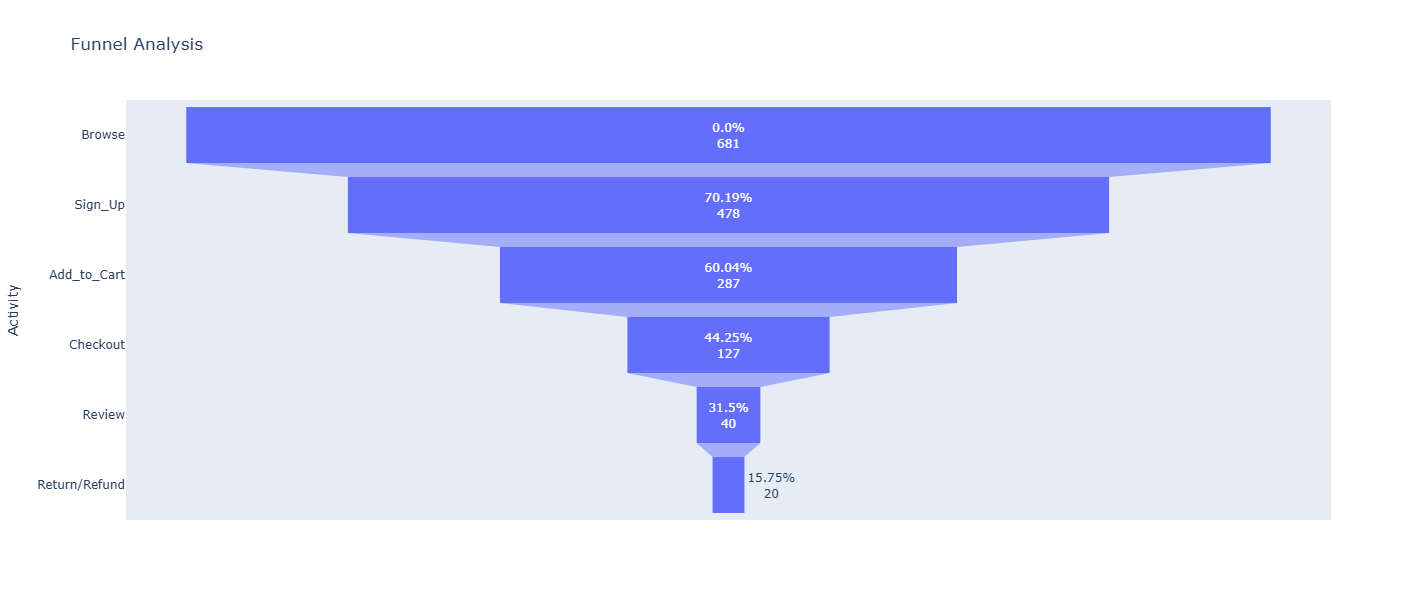

In [61]:
fig  = px.funnel(data_frame=funnel,y='Activity',x='count', text='Per_Conversion'
                 ,title='Funnel Analysis',height=600,hover_data='Avg_Days_2Tran')  
fig.show()   